# Sample Covariance When Variables Are Many

The sample covariance is a scaled cross-product of centered observations, so its rank cannot exceed the smaller available dimension:

$$
S=\frac{1}{T-1}X_c^{\mathsf T}X_c,
\qquad
\operatorname{rank}(S)\leq\min\{N,T-1\}.
$$

Here, $X_c$ is the $T\times N$ centered return matrix; $T$ is the number of dates; $N$ is the number of portfolios. $S$ is the $N\times N$ sample covariance matrix; $\mathsf T$ denotes transpose; $\operatorname{rank}$ counts independent directions.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("10_covariance_denoising");
using CSV, Printf
using RiskLabAI.Data: corr_to_cov,cov_to_corr,denoise_cov,denoised_corr,denoised_corr2,find_max_eval,fit_kde,score_samples,marcenko_pastur_pdf,nercome_denoised_covariance,optimal_portfolio,optimal_portfolio_denoised,pca
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
public_lines = readlines(data_path)
header_row = findfirst(startswith(",Agric"),public_lines)
end_row = findnext(line->isempty(strip(line)),public_lines,header_row+1)
raw = CSV.read(IOBuffer(join(public_lines[header_row:end_row-1],"\n")),DataFrame)
rename!(raw,names(raw)[1]=>"Date")
all_dates = Date.(string.(raw.Date),dateformat"yyyymmdd")
all_returns = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all((all_returns.!=-99.99).&(all_returns.!=-999.0);dims=2))
industry_dates = all_dates[valid]
industry_names = names(raw)[2:end]
industry_returns = all_returns[valid,:]./100
violet = "#C084FC"

function matrix_frame(matrix;metadata...)
    prefix = DataFrame([name=>fill(value,size(matrix,1)) for (name,value) in pairs(metadata)]...)
    return hcat(prefix,DataFrame(row=collect(1:size(matrix,1))),DataFrame(matrix,["x"*string(index) for index in axes(matrix,2)]))
end

function covariance_fit(covariance,q,bandwidth)
    correlation = cov_to_corr(covariance)
    values,vectors = pca(correlation)
    cutoff,variance = find_max_eval(values,q,bandwidth)
    diagnostic = RiskLabAI.Data._mp_bounded_local_min(v->RiskLabAI.Data._mp_pdf_fit_error(v,q,values,bandwidth);derivative=v->RiskLabAI.Data._mp_pdf_fit_gradient(v,q,values,bandwidth))
    @assert variance==(diagnostic.converged ? diagnostic.variance : 1.)
    factors = count(>(cutoff),values)
    return (correlation=correlation,values=values,vectors=vectors,cutoff=cutoff,variance=variance,factors=factors,converged=diagnostic.converged,latent_variance=diagnostic.variance,objective=diagnostic.objective,iterations=diagnostic.iterations)
end

function add_fliers!(figure,groups)
    for (index,values) in enumerate(groups)
        lower,upper = quantile(values,[.25,.75])
        spread = upper-lower
        outside = values[(values.<lower-1.5spread).|(values.>upper+1.5spread)]
        scatter!(figure,fill(index,length(outside)),outside;color=palette.text,markersize=3,markerstrokewidth=0,label=false)
    end
    return figure
end
function box_summary!(figure,groups,colors)
    for (index,values) in enumerate(groups)
        lower,middle,upper = quantile(values,[.25,.5,.75])
        spread = upper-lower
        bottom = minimum(values[values.>=lower-1.5spread])
        top = maximum(values[values.<=upper+1.5spread])
        plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.65,linecolor=palette.text,label=false)
        plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,label=false)
        plot!(figure,[index,index],[bottom,lower];color=palette.text,label=false)
        plot!(figure,[index,index],[upper,top];color=palette.text,label=false)
        for height in (bottom,top)
            plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,label=false)
        end
    end
    return figure
end


box_summary! (generic function with 1 method)

## Public Industry Returns

Row,Field,Value
,String,String
1,Archive,49_Industry_Portfolios_daily_CSV.zip
2,Provider,Kenneth R. French Data Library
3,Provider database vintage,202608 CRSP database
4,Return type,Daily value-weighted return
5,Analysis start,2019-01-02
6,Analysis end,2025-12-31
7,Analysis dates,"1,760"
8,Industry portfolios,49


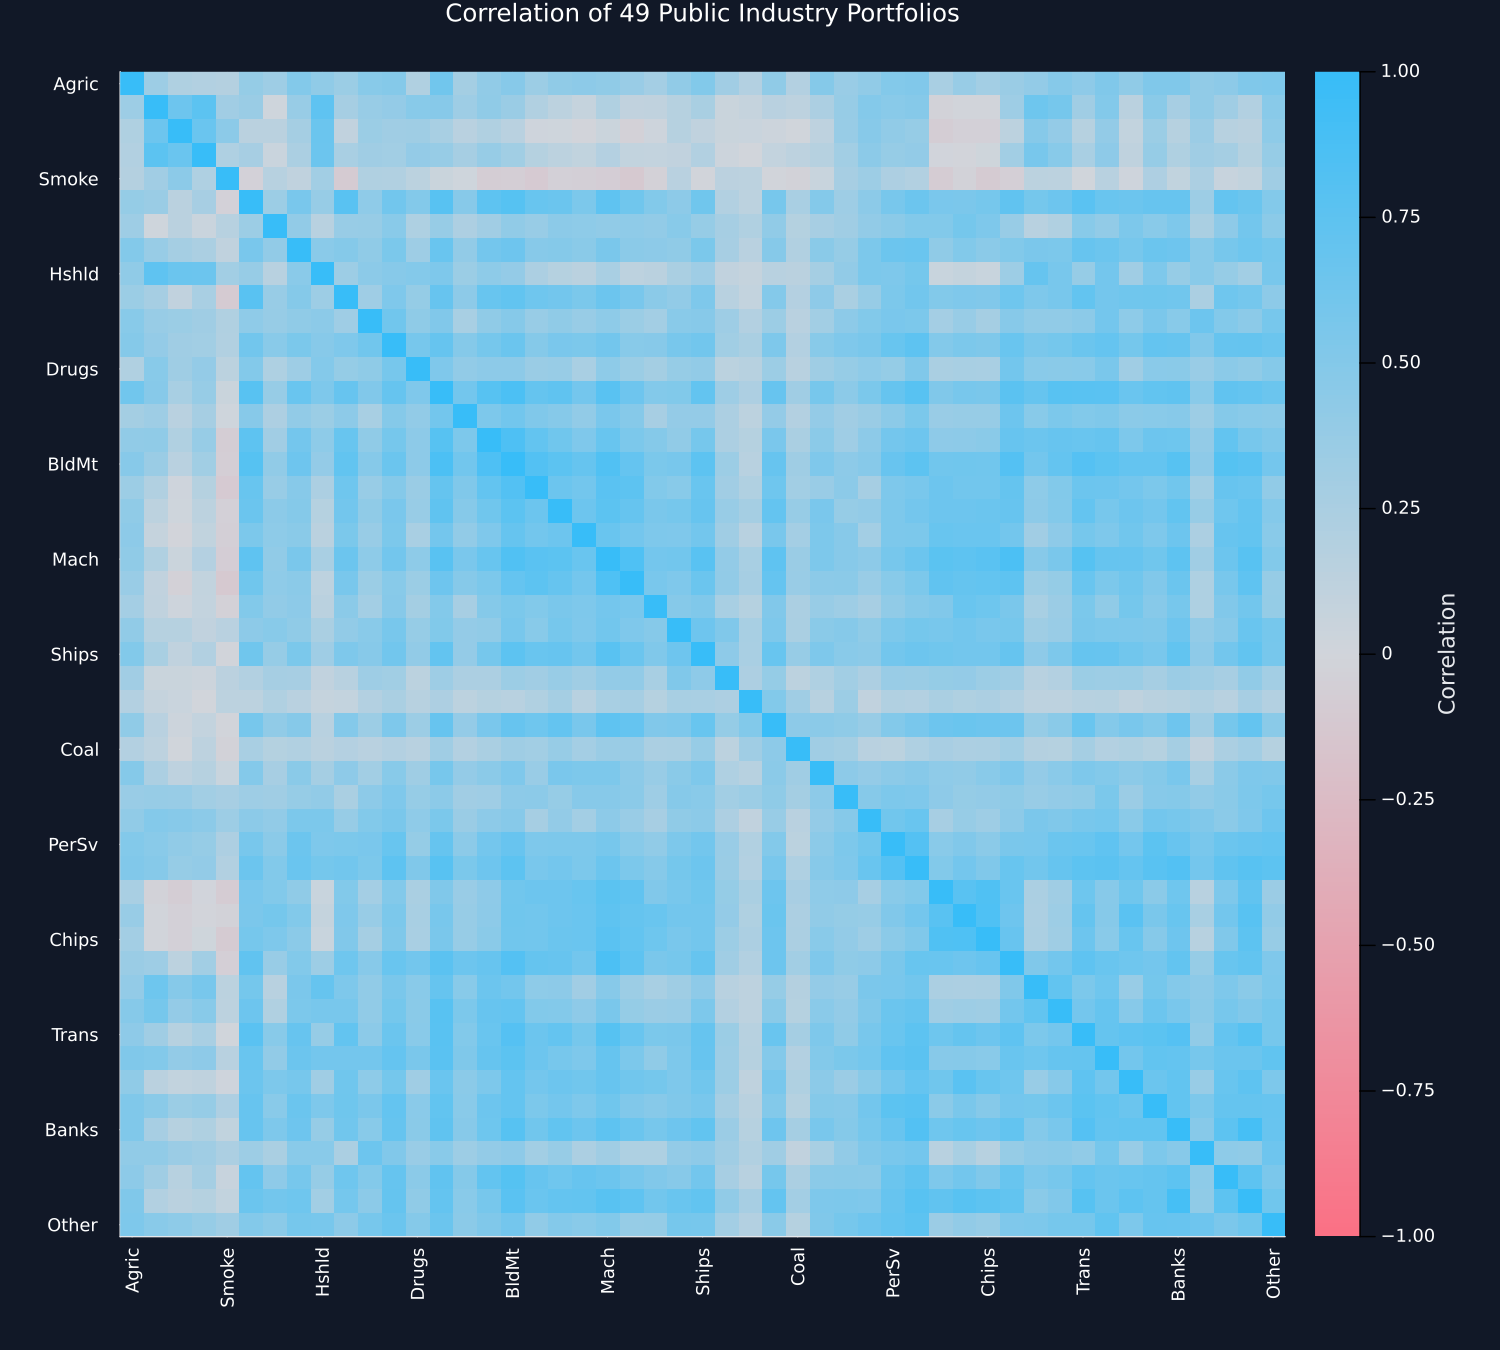

In [2]:
data_provenance = DataFrame("Field"=>["Archive","Provider","Provider database vintage","Return type","Analysis start","Analysis end","Analysis dates","Industry portfolios"],"Value"=>["49_Industry_Portfolios_daily_CSV.zip","Kenneth R. French Data Library","202608 CRSP database","Daily value-weighted return",string(first(industry_dates)),string(last(industry_dates)),"1,760",string(size(industry_returns,2))])
save_table(data_provenance,paths,"data_provenance";caption="Public data used in Chapter 9.",label="tab:chapter9-data-provenance")
correlation_window = industry_returns[end-251:end,:]
correlation = cor(correlation_window)
tick_positions = collect(1:4:49)
figure = heatmap(1:49,1:49,correlation;color=cgrad([palette.rose,"#D1D5DB",palette.cyan]),clims=(-1,1),xticks=(tick_positions,industry_names[tick_positions]),yticks=(tick_positions,industry_names[tick_positions]),xrotation=90,yflip=true,aspect_ratio=:equal,xlims=(.5,49.5),ylims=(.5,49.5),widen=false,title="Correlation of 49 Public Industry Portfolios",colorbar_title="Correlation",size=(1000,900))
save_figure(figure,paths,"industry_correlation")
save_data(hcat(DataFrame(Date=industry_dates),DataFrame(industry_returns,industry_names)),paths,"industry_returns")
save_data(matrix_frame(correlation),paths,"industry_correlation");


## Diagnosing covariance instability

The eigenvalues divide total correlation across directions; the condition number measures spread between the largest and smallest directions:

$$
C=Q\Lambda Q^{\mathsf T},
\qquad
\kappa_2(C)=\frac{\lambda_{\max}}{\lambda_{\min}},
\qquad
r_{\mathrm{eff}}=\exp\!\left(-\sum_{i=1}^{N}\pi_i\log\pi_i\right),
\quad
\pi_i=\frac{\lambda_i}{\sum_{j=1}^{N}\lambda_j}.
$$

Here, Effective rank is the number of equally weighted directions that would have the same eigenvalue entropy. $C$ is a correlation matrix; $Q$ contains orthonormal eigenvectors; $\Lambda$ is diagonal with eigenvalues $\lambda_i.$ $\lambda_{\max},\lambda_{\min}$ are the largest and smallest positive eigenvalues; $\kappa_2$ is the spectral condition number. $\pi_i$ is eigenvalue $i$ divided by their sum; $r_{\mathrm{eff}}$ is effective rank; $N$ is the number of portfolios.

Row,Observations,Portfolios,Observation to portfolio ratio,Rank,Near-zero eigenvalues,Smallest eigenvalue,Largest eigenvalue,Condition number,Effective rank
,Int64,Int64,Float64,Int64,Int64,Float64,Float64,Float64,Float64
1,30,49,0.612245,29,20,-1.7343e-15,21.2608,Inf,8.72241
2,49,49,1.0,48,1,8.96911e-17,17.9145,Inf,12.0073
3,75,49,1.53061,49,0,0.0197643,17.3357,877.126,14.0984
4,125,49,2.55102,49,0,0.0484834,16.8143,346.805,16.3759
5,252,49,5.14286,49,0,0.0434303,24.4043,561.918,10.2618


Row,Ordered direction,Eigenvalue,Share of total correlation,Cumulative share
,Int64,Float64,Float64,Float64
1,1,16.8143,0.343149,0.343149
2,2,6.25128,0.127577,0.470726
3,3,2.48129,0.0506386,0.521365
4,4,1.7606,0.0359307,0.557295
5,5,1.54465,0.0315234,0.588819
6,6,1.49568,0.0305241,0.619343
7,7,1.38298,0.0282241,0.647567
8,8,1.2396,0.025298,0.672865
9,9,1.11527,0.0227606,0.695625


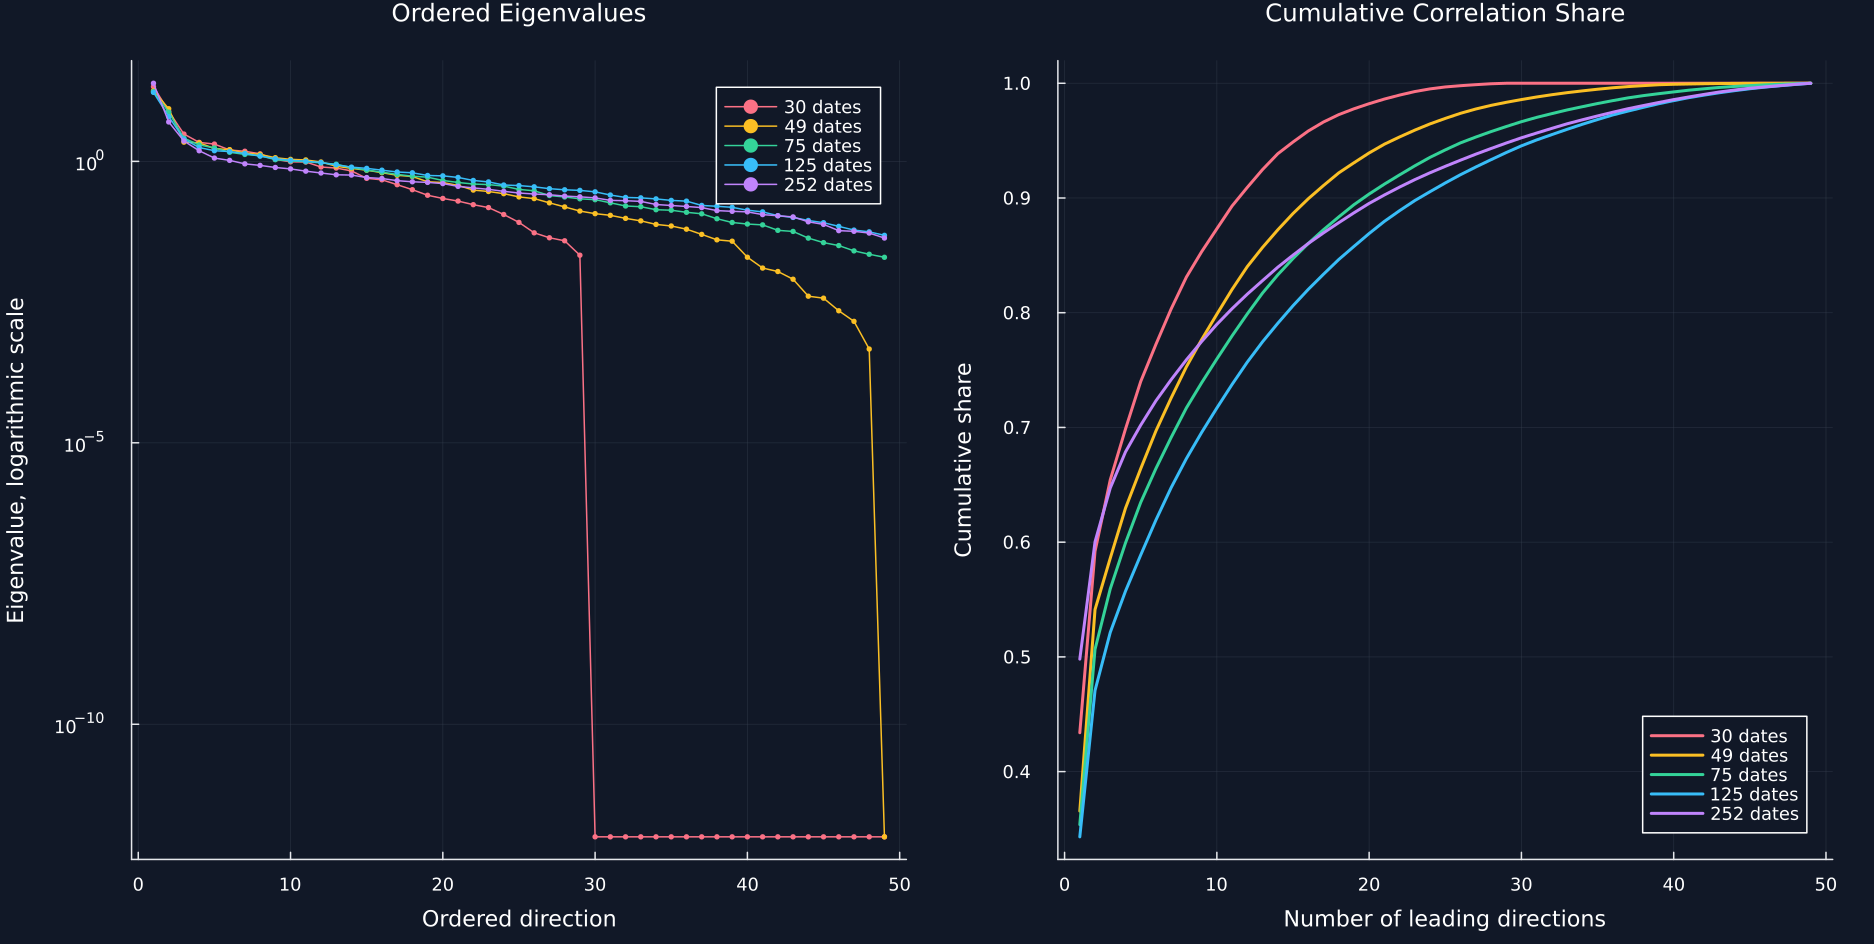

In [3]:
diagnostic_rows,spectral_rows = NamedTuple[],NamedTuple[]
spectra = Dict{Int,Vector{Float64}}()
for observations in [30,49,75,125,252]
    covariance = cov(industry_returns[end-observations+1:end,:])
    current_correlation = cov_to_corr(covariance)
    eigenvalues = sort(eigvals(Symmetric(current_correlation));rev=true)
    spectra[observations] = eigenvalues
    tolerance = first(eigenvalues)*1e-10
    positive = eigenvalues[eigenvalues.>tolerance]
    weights = positive./sum(positive)
    matrix_rank = count(>(tolerance),svdvals(current_correlation))
    condition_number = matrix_rank<49 ? Inf : first(eigenvalues)/last(eigenvalues)
    push!(diagnostic_rows,(observations=observations,portfolios=49,q=observations/49,rank=matrix_rank,near_zero=count(<=(tolerance),eigenvalues),smallest=last(eigenvalues),largest=first(eigenvalues),condition=condition_number,effective=exp(-sum(weights.*log.(weights)))))
    append!(spectral_rows,[(observations=observations,direction=index,eigenvalue=value) for (index,value) in enumerate(eigenvalues)])
end
covariance_window_diagnostics = DataFrame(diagnostic_rows)
rename!(covariance_window_diagnostics,["Observations","Portfolios","Observation to portfolio ratio","Rank","Near-zero eigenvalues","Smallest eigenvalue","Largest eigenvalue","Condition number","Effective rank"])
shares = spectra[125]./sum(spectra[125])
leading_eigenvalues = DataFrame("Ordered direction"=>1:10,"Eigenvalue"=>spectra[125][1:10],"Share of total correlation"=>shares[1:10],"Cumulative share"=>cumsum(shares[1:10]))
save_table(covariance_window_diagnostics,paths,"covariance_window_diagnostics";caption="Rank and eigenvalue diagnostics as the public estimation window changes.",label="tab:chapter9-window-diagnostics")
save_table(leading_eigenvalues,paths,"leading_eigenvalues";caption="Ten leading correlation eigenvalues in the 125-day public window.",label="tab:chapter9-leading-eigenvalues")
save_data(DataFrame(spectral_rows),paths,"window_eigenvalue_spectra")
p1 = plot(;yscale=:log10,title="Ordered Eigenvalues",xlabel="Ordered direction",ylabel="Eigenvalue, logarithmic scale",legend=:topright)
p2 = plot(;title="Cumulative Correlation Share",xlabel="Number of leading directions",ylabel="Cumulative share",legend=:bottomright)
for (observations,color) in zip([30,49,75,125,252],[palette.rose,palette.amber,palette.green,palette.cyan,violet])
    plot!(p1,1:49,max.(spectra[observations],1e-12);color,label=string(observations)*" dates",marker=:circle,markersize=2,markerstrokewidth=0,linewidth=1)
    plot!(p2,1:49,cumsum(max.(spectra[observations],0))./sum(max.(spectra[observations],0));color,label=string(observations)*" dates")
end
save_figure(plot(p1,p2;layout=(1,2),size=(1250,630)),paths,"window_eigenvalue_spectra")


## Tests

In [4]:
@assert size(industry_returns)==(1760,49)
@assert first(industry_dates)==Date(2019,1,2)
@assert last(industry_dates)==Date(2025,12,31)
@assert all(isfinite,industry_returns)
@assert diag(correlation)≈ones(49)
@assert correlation≈transpose(correlation)
@assert covariance_window_diagnostics.Rank[1]==29
@assert covariance_window_diagnostics.Rank[2]==48
@assert covariance_window_diagnostics.Rank[3]==49
@assert covariance_window_diagnostics[1:2,"Near-zero eigenvalues"]==[20,1]
@assert all(covariance_window_diagnostics[!,"Largest eigenvalue"].>1)
@assert all(1 .<=covariance_window_diagnostics[!,"Effective rank"].<=49)
@assert sum(spectra[125])≈49
@assert all(diff(spectra[125]).<=0)
@assert all(diff(leading_eigenvalues[!,"Cumulative share"]).>=0)
@assert isfile(joinpath(paths.figures,"industry_correlation.pdf"))
@assert isfile(joinpath(paths.figures,"window_eigenvalue_spectra.pdf"))
@assert isfile(joinpath(paths.tables,"data_provenance.tex"))
@assert isfile(joinpath(paths.tables,"covariance_window_diagnostics.tex"))
@assert isfile(joinpath(paths.tables,"leading_eigenvalues.tex"))
